# Checkpoint 1

## Data Source

Dataset: Lahman Baseball Database (Society for American Baseball Research — SABR)
https://sabr.org/lahman-database/

This dataset contains historical MLB statistics from 1871 through 2025.
Specifically, we will be looking at the following statistics:
* Team Performance ([Teams.csv](https://github.com/FirstTimeGaming/ISC-2310-Group-Project/blob/main/data/raw/Teams.csv))
* Individual Batting Statistics ([Batting.csv](https://github.com/FirstTimeGaming/ISC-2310-Group-Project/blob/main/data/raw/Batting.csv))
* Individual Pitching Statistics ([Pitching.csv](https://github.com/FirstTimeGaming/ISC-2310-Group-Project/blob/main/data/raw/Pitching.csv))

## Questions to Answer

With this dataset, we will answer the following questions:

* How strongly does a team's offense correlate to its win rate?
* How strongly does a team's pitching correlate to its win rate?
* Does offense or pitching have a greater effect on a team's win rate?



## Setup


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



## Data cleaning

### Pitching


In [3]:
# Cleaned Pitching Dataset
# ERA = earned runs per nine innings (lower is better).

pitching = pd.read_csv("data/raw/Pitching.csv")

print("Original Dataset:")
print(pitching.head())
print("\nDataset Size:")
print(pitching.shape)
print("\nDataset Information:")
pitching.info()
print("\nMissing Values:")
print(pitching.isnull().sum())

pitching = pitching.drop_duplicates()

pitching = pitching[[
    "yearID", "teamID", "W", "L", "G",
    "IPouts", "H", "ER", "HR", "BB", "SO",
]]

pitching = pitching.fillna(0)

team_pitching = pitching.groupby(["yearID", "teamID"], as_index=False).sum()

team_pitching["IP"] = team_pitching["IPouts"] / 3
team_pitching["ERA"] = (
    team_pitching["ER"] * 9
) / team_pitching["IP"].replace(0, 1)

print("\nCleaned Pitching Dataset:")
print(team_pitching.head())
print("\nDescriptive Statistics:")
print(team_pitching.describe())
print("\nMissing Values After Cleaning:")
print(team_pitching.isnull().sum())
print("\nFinal Dataset Size:")
print(team_pitching.shape)

team_pitching.to_csv("data/cleaned/Cleaned_Team_Pitching.csv", index=False)
print("\nCleaned pitching dataset saved to data/cleaned/Cleaned_Team_Pitching.csv")



Original Dataset:
    playerID  yearID  stint teamID lgID  W  L   G  GS  CG  ...  IBB   WP  HBP  \
0  aardsda01    2004      1    SFN   NL  1  0  11   0   0  ...  0.0  0.0  2.0   
1  aardsda01    2006      1    CHN   NL  3  0  45   0   0  ...  0.0  1.0  1.0   
2  aardsda01    2007      1    CHA   AL  2  1  25   0   0  ...  3.0  2.0  1.0   
3  aardsda01    2008      1    BOS   AL  4  2  47   0   0  ...  2.0  3.0  5.0   
4  aardsda01    2009      1    SEA   AL  3  6  73   0   0  ...  3.0  2.0  0.0   

    BK    BFP    GF   R   SH   SF  GIDP  
0  0.0   61.0   5.0   8  0.0  1.0   1.0  
1  0.0  225.0   9.0  25  1.0  3.0   2.0  
2  0.0  151.0   7.0  24  2.0  1.0   1.0  
3  0.0  228.0   7.0  32  3.0  2.0   4.0  
4  0.0  296.0  53.0  23  2.0  1.0   2.0  

[5 rows x 30 columns]

Dataset Size:
(57630, 30)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 57630 entries, 0 to 57629
Data columns (total 30 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  ---

### Batting


In [4]:
# Cleaned Batting Dataset
# Aggregate individual batting lines to team-year totals and attach team records.

batting = pd.read_csv("data/raw/Batting.csv")

print("Original Dataset:")
print(batting.head())
print("\nDataset Size:")
print(batting.shape)
print("\nDataset Information:")
batting.info()
print("\nMissing Values:")
print(batting.isnull().sum())

batting = batting.drop_duplicates()

batting_cols = [
    "yearID", "teamID", "G", "AB", "R", "H", "2B", "3B", "HR",
    "RBI", "BB", "SO", "SB", "CS", "HBP", "SF",
]
batting = batting[batting_cols].fillna(0)

team_batting = batting.groupby(["yearID", "teamID"], as_index=False).sum()

teams = pd.read_csv("data/raw/Teams.csv")
team_records = teams[["yearID", "teamID", "W", "L", "G"]].drop_duplicates()

# Player games summed; use team G from Teams.csv for per-game rates.
team_batting = team_batting.merge(
    team_records,
    on=["yearID", "teamID"],
    how="left",
    suffixes=("_player", "_team"),
)
team_batting = team_batting.rename(columns={"G_team": "G"})
team_batting = team_batting.drop(columns=["G_player"])

team_batting["WinPct"] = team_batting["W"] / (
    team_batting["W"] + team_batting["L"]
).replace(0, pd.NA)

print("\nCleaned Batting Dataset:")
print(team_batting.head())
print("\nDescriptive Statistics:")
print(team_batting.describe())
print("\nMissing Values After Cleaning:")
print(team_batting.isnull().sum())
print("\nFinal Dataset Size:")
print(team_batting.shape)

team_batting.to_csv("data/cleaned/Cleaned_Team_Batting.csv", index=False)
print("\nCleaned batting dataset saved to data/cleaned/Cleaned_Team_Batting.csv")



Original Dataset:
    playerID  yearID  stint teamID lgID   G  AB  R  H  2B  ...  RBI   SB   CS  \
0  aardsda01    2004      1    SFN   NL  11   0  0  0   0  ...  0.0  0.0  0.0   
1  aardsda01    2006      1    CHN   NL  45   2  0  0   0  ...  0.0  0.0  0.0   
2  aardsda01    2007      1    CHA   AL  25   0  0  0   0  ...  0.0  0.0  0.0   
3  aardsda01    2008      1    BOS   AL  47   1  0  0   0  ...  0.0  0.0  0.0   
4  aardsda01    2009      1    SEA   AL  73   0  0  0   0  ...  0.0  0.0  0.0   

   BB   SO  IBB  HBP   SH   SF  GIDP  
0   0  0.0  0.0  0.0  0.0  0.0   0.0  
1   0  0.0  0.0  0.0  1.0  0.0   0.0  
2   0  0.0  0.0  0.0  0.0  0.0   0.0  
3   0  1.0  0.0  0.0  0.0  0.0   0.0  
4   0  0.0  0.0  0.0  0.0  0.0   0.0  

[5 rows x 22 columns]

Dataset Size:
(128598, 22)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 128598 entries, 0 to 128597
Data columns (total 22 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   pla

## Analysis

### Pitching trends


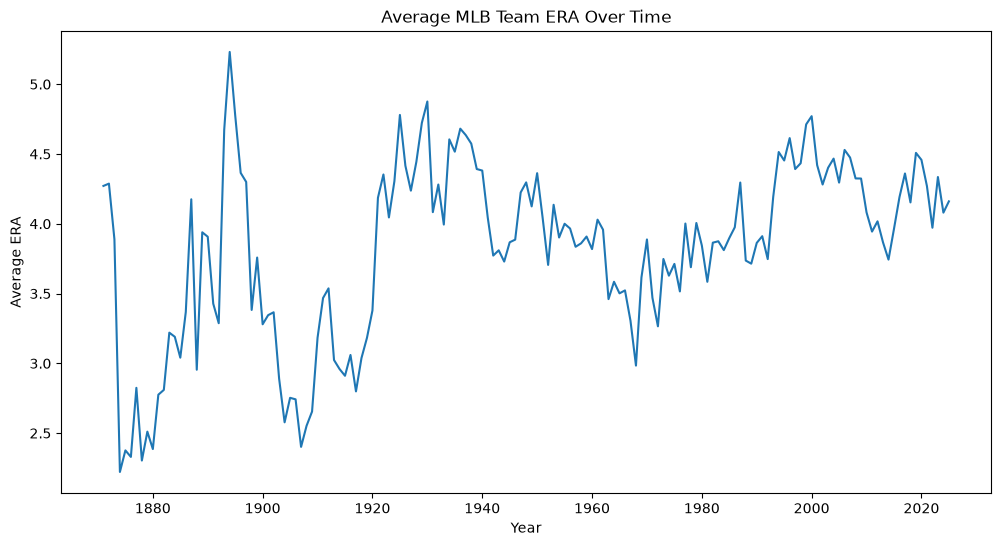

In [5]:
era_by_year = team_pitching.groupby("yearID")["ERA"].mean()

era_by_year.plot(
    kind="line",
    figsize=(12, 6),
    title="Average MLB Team ERA Over Time",
    xlabel="Year",
    ylabel="Average ERA",
)
plt.show()



### Pitching and win percentage


In [6]:
team_pitching["WinPct"] = (
    team_pitching["W"] / (team_pitching["W"] + team_pitching["L"])
)

print(team_pitching.head())
print("\nWin Percentage Statistics:")
print(team_pitching["WinPct"].describe())



   yearID teamID   W   L   G  IPouts    H   ER    HR  BB  SO     IP       ERA  \
0    1871    BS1  20  10  40     828  367  109   2.0  42  23  276.0  3.554348   
1    1871    CH1  19   9  31     753  308   77   6.0  28  22  251.0  2.760956   
2    1871    CL1  10  19  35     762  346  116  13.0  53  34  254.0  4.110236   
3    1871    FW1   6  11  19     507  261   97   5.0  21  17  169.0  5.165680   
4    1871    NY2  16  17  34     879  373  121   7.0  42  22  293.0  3.716724   

     WinPct  
0  0.666667  
1  0.678571  
2  0.344828  
3  0.352941  
4  0.484848  

Win Percentage Statistics:
count    3613.000000
mean        0.497434
std         0.109168
min         0.000000
25%         0.437500
50%         0.503106
75%         0.565789
max         1.000000
Name: WinPct, dtype: float64


In [7]:
team_pitching["SO_per_game"] = team_pitching["SO"] / team_pitching["G"]
team_pitching["BB_per_game"] = team_pitching["BB"] / team_pitching["G"]
team_pitching["H_per_game"] = team_pitching["H"] / team_pitching["G"]

print(team_pitching[[
    "yearID", "teamID", "ERA",
    "SO_per_game", "BB_per_game", "H_per_game", "WinPct",
]].head())



   yearID teamID       ERA  SO_per_game  BB_per_game  H_per_game    WinPct
0    1871    BS1  3.554348     0.575000     1.050000    9.175000  0.666667
1    1871    CH1  2.760956     0.709677     0.903226    9.935484  0.678571
2    1871    CL1  4.110236     0.971429     1.514286    9.885714  0.344828
3    1871    FW1  5.165680     0.894737     1.105263   13.736842  0.352941
4    1871    NY2  3.716724     0.647059     1.235294   10.970588  0.484848


In [8]:
pitching_stats = ["ERA", "SO_per_game", "BB_per_game", "H_per_game"]

pitching_correlations = team_pitching[pitching_stats + ["WinPct"]].corr()

print("Pitching Correlations with Win Percentage:")
print(pitching_correlations["WinPct"].drop("WinPct").sort_values())



Pitching Correlations with Win Percentage:
ERA           -0.539657
H_per_game    -0.133213
BB_per_game   -0.074632
SO_per_game    0.221205
Name: WinPct, dtype: float64


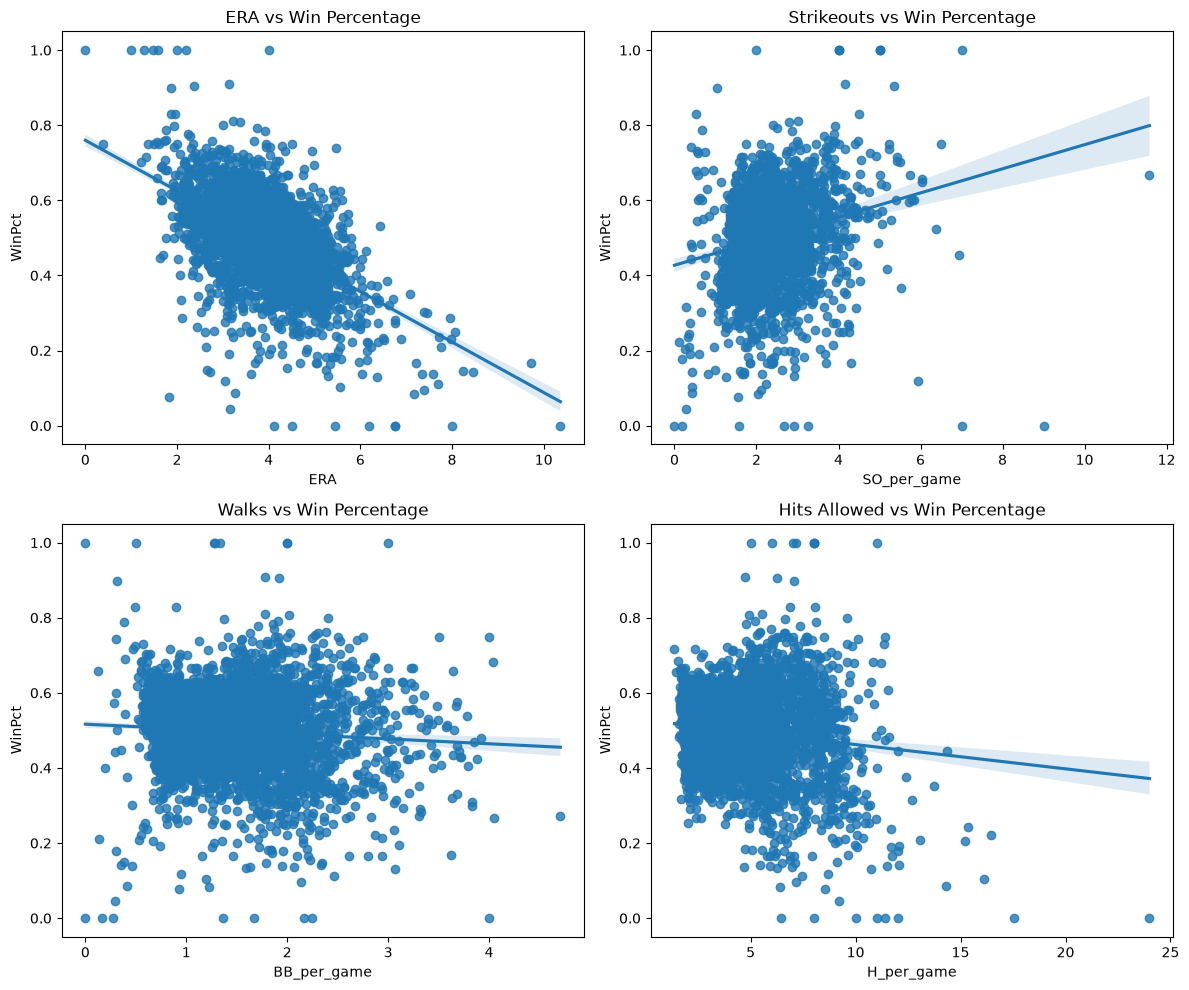

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

sns.regplot(data=team_pitching, x="ERA", y="WinPct", ax=axes[0, 0])
axes[0, 0].set_title("ERA vs Win Percentage")

sns.regplot(data=team_pitching, x="SO_per_game", y="WinPct", ax=axes[0, 1])
axes[0, 1].set_title("Strikeouts vs Win Percentage")

sns.regplot(data=team_pitching, x="BB_per_game", y="WinPct", ax=axes[1, 0])
axes[1, 0].set_title("Walks vs Win Percentage")

sns.regplot(data=team_pitching, x="H_per_game", y="WinPct", ax=axes[1, 1])
axes[1, 1].set_title("Hits Allowed vs Win Percentage")

plt.tight_layout()
plt.show()



### Batting trends

In [10]:

# Calculate batting performance statistics

# Calculates batting average
team_batting["BA"] = (
    team_batting["H"] /
    team_batting["AB"].replace(0, 1)
)

# Calculates on-base percentage
team_batting["OBP"] = (
    team_batting["H"] +
    team_batting["BB"] +
    team_batting["HBP"]
) / (
    team_batting["AB"] +
    team_batting["BB"] +
    team_batting["HBP"] +
    team_batting["SF"]
).replace(0, 1)

# Calculates slugging percentage
team_batting["SLG"] = (
    team_batting["H"] +
    team_batting["2B"] +
    2 * team_batting["3B"] +
    3 * team_batting["HR"]
) / team_batting["AB"].replace(0, 1)

# Calculates on-base plus slugging
team_batting["OPS"] = (
    team_batting["OBP"] +
    team_batting["SLG"]
)

# Calculates runs per game
team_batting["R_per_game"] = (
    team_batting["R"] / team_batting["G"]
)

# Calculates home runs per game
team_batting["HR_per_game"] = (
    team_batting["HR"] / team_batting["G"]
)

# Calculates walks per game
team_batting["BB_per_game"] = (
    team_batting["BB"] / team_batting["G"]
)

# Displays batting statistics
print("Team Batting Performance:")
print(team_batting[[
    "yearID", "teamID", "WinPct",
    "BA", "OBP", "SLG", "OPS",
    "R_per_game", "HR_per_game", "BB_per_game"
]].head())


Team Batting Performance:
   yearID teamID    WinPct        BA       OBP       SLG       OPS  \
0    1871    BS1  0.666667  0.310496  0.339385  0.422012  0.761397   
1    1871    CH1  0.678571  0.270067  0.304936  0.373746  0.678682   
2    1871    CL1  0.344828  0.276560  0.292079  0.391231  0.683310   
3    1871    FW1  0.368421  0.238606  0.270860  0.293566  0.564426   
4    1871    NY2  0.484848  0.287037  0.303410  0.349715  0.653125   

   R_per_game  HR_per_game  BB_per_game  
0   12.935484     0.096774     1.935484  
1   10.785714     0.357143     2.142857  
2    8.586207     0.241379     0.896552  
3    7.210526     0.105263     1.736842  
4    9.151515     0.030303     1.000000  


In [11]:

# Calculate correlations between batting statistics and WinPct

batting_correlations = team_batting[[
    "BA", "OBP", "SLG", "OPS",
    "R_per_game", "HR_per_game", "BB_per_game",
    "WinPct"
]].corr()

# Displays correlations with WinPct
print("Batting Correlations with Win Percentage:")
print(batting_correlations["WinPct"].sort_values(ascending=False))


Batting Correlations with Win Percentage:
WinPct         1.000000
OBP            0.470097
OPS            0.468889
BA             0.448275
SLG            0.419304
R_per_game     0.273607
BB_per_game    0.176177
HR_per_game    0.168402
Name: WinPct, dtype: float64


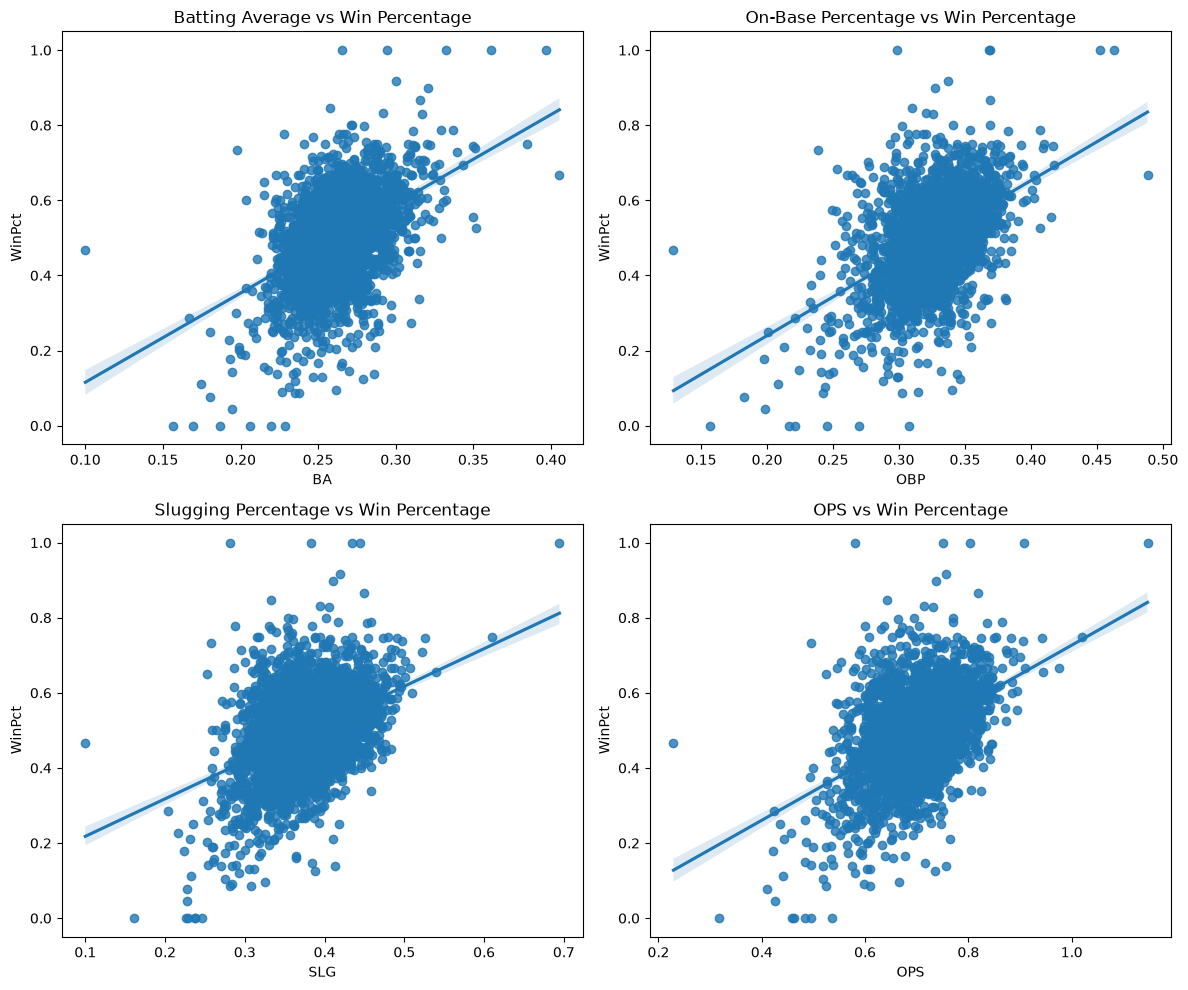

In [12]:
# Create batting regression plots

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

sns.regplot(data=team_batting, x="BA", y="WinPct", ax=axes[0, 0])
axes[0, 0].set_title("Batting Average vs Win Percentage")

sns.regplot(data=team_batting, x="OBP", y="WinPct", ax=axes[0, 1])
axes[0, 1].set_title("On-Base Percentage vs Win Percentage")

sns.regplot(data=team_batting, x="SLG", y="WinPct", ax=axes[1, 0])
axes[1, 0].set_title("Slugging Percentage vs Win Percentage")

sns.regplot(data=team_batting, x="OPS", y="WinPct", ax=axes[1, 1])
axes[1, 1].set_title("OPS vs Win Percentage")

plt.tight_layout()
plt.show()

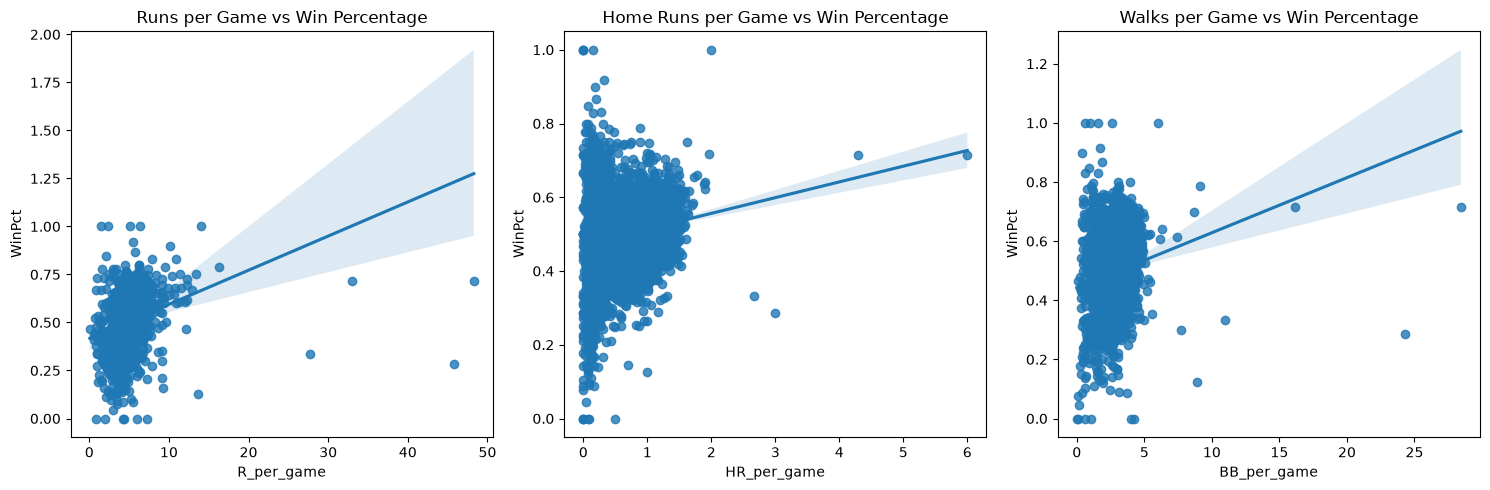

In [13]:
# Create additional batting regression plots

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.regplot(data=team_batting, x="R_per_game", y="WinPct", ax=axes[0])
axes[0].set_title("Runs per Game vs Win Percentage")

sns.regplot(data=team_batting, x="HR_per_game", y="WinPct", ax=axes[1])
axes[1].set_title("Home Runs per Game vs Win Percentage")

sns.regplot(data=team_batting, x="BB_per_game", y="WinPct", ax=axes[2])
axes[2].set_title("Walks per Game vs Win Percentage")

plt.tight_layout()
plt.show()